# Advanced Data Preparation with Python (Car Data)

This notebook demonstrates advanced data preparation techniques with pandas using scraped car data from AutoScout24. It is an exercise: complete the empty code cells by applying the steps from the apartment data solution notebook (advanced_data_preparation_apartment_data_solution.ipynb). 
We will cover the following operations:

- Extracting information from raw data using regular expressions
- Counting and removing missing and duplicated values
- Creating new variables using string manipulation
- Discretization and One Hot Encoding
- Scaling and standardization
- Transformations (log, square root, Box-Cox)
- Combining data using .merge()
- Sorting, reshaping and pivoting data

## Libraries and settings

In [1]:
# Libraries
import os
import re
import time
import fnmatch
import numpy as np
import pandas as pd
import seaborn as sns
from datetime import datetime
import matplotlib.pyplot as plt

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Get current working directory
print(os.getcwd())

/workspaces/python_data_preparation


## Importing data

In [2]:
# Import data from csv to pandas dataframe named 'df'
df = pd.read_csv('./Data/autoscout24_data.csv', sep=";", encoding='utf-8')

# Change the column names to lowercase
df.columns = df.columns.str.lower()

# Display the first 5 rows of the dataframe
df.head()


,url_short,offer_id,scrape_dt,type,price_raw,hp_raw,init_regist,mileage_raw,fuel_type,transmission,dealer_name,dealer_plz,dealer_city,dealer_street_house_nr,dealer_telnr,init_regist_my,init_regist_month,init_regist_year,init_regist_dt
0,https://www.autoscout24.ch/7324420,7324420,2020_03_17 07:34:45,AUDI A5 Sportback 3.0 TDI quattro S-tronic (Li...,CHF 22'500.–,245 PS,10.2014,75'000 km,Diesel,Automatisiertes Schaltgetriebe,***confidential***,8488,Turbenthal,Mettlenstrasse 3,***confidential***,10.2014,10.0,2014.0,2014-10
1,https://www.autoscout24.ch/7512768,7512768,2020_03_17 07:34:55,MERCEDES-BENZ SLK 200 7G-Tronic (Cabriolet),CHF 23'749.–,184 PS,6.2013,46'655 km,Benzin,Automat sequentiell,***confidential***,3186,Düdingen,Brugerastrasse 60,***confidential***,6.2013,6.0,2013.0,2013-06
2,https://www.autoscout24.ch/7512034,7512034,2020_03_17 07:35:03,MERCEDES-BENZ C 350 Avantgarde 4Matic 7G-Troni...,CHF 18'500.–,306 PS,6.2011,138'955 km,Benzin,Automat sequentiell,***confidential***,1262,Eysins,1262 Eysins,***confidential***,6.2011,6.0,2011.0,2011-06
3,https://www.autoscout24.ch/7512728,7512728,2020_03_17 07:35:06,MERCEDES-BENZ A 45 AMG 4Matic Speedshift 7G-DC...,CHF 36'000.–,360 PS,8.2015,43'000 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,4314,Zeiningen,Am Stutz 21,***confidential***,8.2015,8.0,2015.0,2015-08
4,https://www.autoscout24.ch/7490242,7490242,2020_03_17 07:35:16,AUDI A5 Sportback 2.0 TFSI Sport quattro S-tro...,CHF 48'500.–,252 PS,9.2018,43'300 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,3250,Lyss,3250 Lyss,***confidential***,9.2018,9.0,2018.0,2018-09


## Count number of rows and columns in the data frame

In [3]:
# Count number of rows and columns in the data frame
df.info()

#ODER
df.shape[1] #ODER mit 0 für Zellen

<class 'pandas.DataFrame'>
RangeIndex: 3980 entries, 0 to 3979
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   url_short               3980 non-null   str    
 1   offer_id                3980 non-null   int64  
 2   scrape_dt               3980 non-null   str    
 3   type                    3980 non-null   str    
 4   price_raw               3980 non-null   str    
 5   hp_raw                  3980 non-null   str    
 6   init_regist             3980 non-null   str    
 7   mileage_raw             3980 non-null   str    
 8   fuel_type               3980 non-null   str    
 9   transmission            3980 non-null   str    
 10  dealer_name             3980 non-null   str    
 11  dealer_plz              3980 non-null   int64  
 12  dealer_city             3980 non-null   str    
 13  dealer_street_house_nr  3978 non-null   str    
 14  dealer_telnr            3980 non-null   str    
 15

19

## Get data types (raw-format from web scraper)

In [4]:
# Get data types of each column
df.dtypes

url_short                     str
offer_id                    int64
scrape_dt                     str
type                          str
price_raw                     str
hp_raw                        str
init_regist                   str
mileage_raw                   str
fuel_type                     str
transmission                  str
dealer_name                   str
dealer_plz                  int64
dealer_city                   str
dealer_street_house_nr        str
dealer_telnr                  str
init_regist_my                str
init_regist_month         float64
init_regist_year          float64
init_regist_dt                str
dtype: object

## Extract information from raw data using regular expressions (regex)

### Extract numerical values from mileage_raw

In [5]:
# Extract numerical values (note the 'join' function)
mileage=[]
for i in df['mileage_raw']:
    i= i.replace("'","")
    d1=re.findall(r'\d+',i)
    try:
        d2=int(d1[0])
    except:
        d2=None
    mileage.append(d2)

# Save as new variable in the pandas data frame
df['mileage'] = pd.Series(mileage, dtype='Int64')   

# Show first records of data frame
df[['mileage_raw','mileage']].head()

,mileage_raw,mileage
0,75'000 km,75000
1,46'655 km,46655
2,138'955 km,138955
3,43'000 km,43000
4,43'300 km,43300


### Extract numerical values from hp_raw

In [6]:
df

,url_short,offer_id,scrape_dt,type,price_raw,hp_raw,init_regist,mileage_raw,fuel_type,transmission,dealer_name,dealer_plz,dealer_city,dealer_street_house_nr,dealer_telnr,init_regist_my,init_regist_month,init_regist_year,init_regist_dt,mileage
0,https://www.autoscout24.ch/7324420,7324420,2020_03_17 07:34:45,AUDI A5 Sportback 3.0 TDI quattro S-tronic (Li...,CHF 22'500.–,245 PS,10.2014,75'000 km,Diesel,Automatisiertes Schaltgetriebe,***confidential***,8488,Turbenthal,Mettlenstrasse 3,***confidential***,10.2014,10.0,2014.0,2014-10,75000
1,https://www.autoscout24.ch/7512768,7512768,2020_03_17 07:34:55,MERCEDES-BENZ SLK 200 7G-Tronic (Cabriolet),CHF 23'749.–,184 PS,6.2013,46'655 km,Benzin,Automat sequentiell,***confidential***,3186,Düdingen,Brugerastrasse 60,***confidential***,6.2013,6.0,2013.0,2013-06,46655
2,https://www.autoscout24.ch/7512034,7512034,2020_03_17 07:35:03,MERCEDES-BENZ C 350 Avantgarde 4Matic 7G-Troni...,CHF 18'500.–,306 PS,6.2011,138'955 km,Benzin,Automat sequentiell,***confidential***,1262,Eysins,1262 Eysins,***confidential***,6.2011,6.0,2011.0,2011-06,138955
3,https://www.autoscout24.ch/7512728,7512728,2020_03_17 07:35:06,MERCEDES-BENZ A 45 AMG 4Matic Speedshift 7G-DC...,CHF 36'000.–,360 PS,8.2015,43'000 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,4314,Zeiningen,Am Stutz 21,***confidential***,8.2015,8.0,2015.0,2015-08,43000
4,https://www.autoscout24.ch/7490242,7490242,2020_03_17 07:35:16,AUDI A5 Sportback 2.0 TFSI Sport quattro S-tro...,CHF 48'500.–,252 PS,9.2018,43'300 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,3250,Lyss,3250 Lyss,***confidential***,9.2018,9.0,2018.0,2018-09,43300
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3975,https://www.autoscout24.ch/7137137,7137137,2020_03_17 06:03:15,FERRARI F360 Spider (Cabriolet),CHF 58'400.–,400 PS,2.2002,78'000 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,8852,Altendorf,8852 Altendorf,***confidential***,2.2002,2.0,2002.0,2002-02,78000
3976,https://www.autoscout24.ch/6758841,6758841,2020_03_17 07:15:07,MERCEDES-BENZ SL 500 560 SL (Cabriolet),CHF 15'900.–,232 PS,1.1987,315'000 km,Benzin,Automatik-Getriebe,***confidential***,9444,DIEPOLDSAU,WERKSTRASSE 10 1,***confidential***,1.1987,1.0,1987.0,1987-01,315000
3977,https://www.autoscout24.ch/7461330,7461330,2020_03_17 07:18:31,MERCEDES-BENZ CL 63 AMG 7G-Tronic (Coupé),CHF 42'000.–,525 PS,8.2007,85'000 km,Benzin,Automat sequentiell,***confidential***,8953,Dietikon,8953 Dietikon,***confidential***,8.2007,8.0,2007.0,2007-08,85000
3978,https://www.autoscout24.ch/7005403,7005403,2020_03_17 07:30:54,BMW 328i Cabrio (Cabriolet),CHF 9'980.–,193 PS,8.1995,188'920 km,Benzin,Schaltgetriebe manuell,***confidential***,2543,Lengnau,Mühleweg 8,***confidential***,8.1995,8.0,1995.0,1995-08,188920


In [7]:
# Extract numerical values (note the 'join' function)
hp=[]
for i in df['hp_raw']:
    d1=re.findall(r'\d+',i)
    try:
        d2=int(d1[0])
    except:
        d2=None
    hp.append(d2)

# Save as new variable in the pandas data frame
df['hp'] = pd.Series(hp, dtype='Int64')   

# Show first records of data frame
df[['hp_raw','hp']].head()


,hp_raw,hp
0,245 PS,245
1,184 PS,184
2,306 PS,306
3,360 PS,360
4,252 PS,252


### Extract numerical values from price_raw

In [8]:
# Extract numerical values using a regular expression
price=[]
for i in df['price_raw']:
    i= i.replace("'","")
    d1=re.findall(r'\d+',i)
    try:
        d2=int(d1[0])
    except:
        d2=None
    price.append(d2)

# Save as new variable in the pandas data frame
df['price'] = pd.Series(price, dtype='Int64')

# Show first records of data frame
df[['price_raw','price']].head()

,price_raw,price
0,CHF 22'500.–,22500
1,CHF 23'749.–,23749
2,CHF 18'500.–,18500
3,CHF 36'000.–,36000
4,CHF 48'500.–,48500


### Get data types of all variables, including the new ones

In [9]:
# Get data types of all variables
df.dtypes


url_short                     str
offer_id                    int64
scrape_dt                     str
type                          str
price_raw                     str
hp_raw                        str
init_regist                   str
mileage_raw                   str
fuel_type                     str
transmission                  str
dealer_name                   str
dealer_plz                  int64
dealer_city                   str
dealer_street_house_nr        str
dealer_telnr                  str
init_regist_my                str
init_regist_month         float64
init_regist_year          float64
init_regist_dt                str
mileage                     Int64
hp                          Int64
price                       Int64
dtype: object

## Count and remove missing values

In [10]:
# Count and remove missing values
print("Missing values before removing: ", df.isnull().sum().sum()) #hats überhaupt 0  Werte, zweites sum ist damit es alle fehlenden werte zusammenzählt.

#wenn ja dann löscht man raus
df=df.dropna()

print("Missing values after removing: ", df.isnull().sum().sum())
# Reset the index of the dataframe
df=df.reset_index(drop=True)

Missing values before removing:  23
Missing values after removing:  0


## Count and remove duplicated values

In [11]:
# Count and remove duplicates
print("No of dupl. before Remove: ",df.duplicated().sum())
df=df.drop_duplicates()
print("No of dupl. afer Remove: ",df.duplicated().sum())

# Reset the index of the dataframe
df=df.reset_index(drop=True)

No of dupl. before Remove:  0
No of dupl. afer Remove:  0


## Use string manipulation methods to create additional variables from the car type

### Change strings in 'type' to uppercase

In [12]:
# Change strings in 'type' to uppercase and remove leading/trailing spaces
df['type']=df['type'].str.upper().str.strip() #upper damit alle buchstaben gross und strip für ohne 

# Display variable 'type'
df['type'].head()

0    AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...
1          MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET)
2    MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...
3    MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...
4    AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...
Name: type, dtype: str

### Calculate length of strings in 'type'

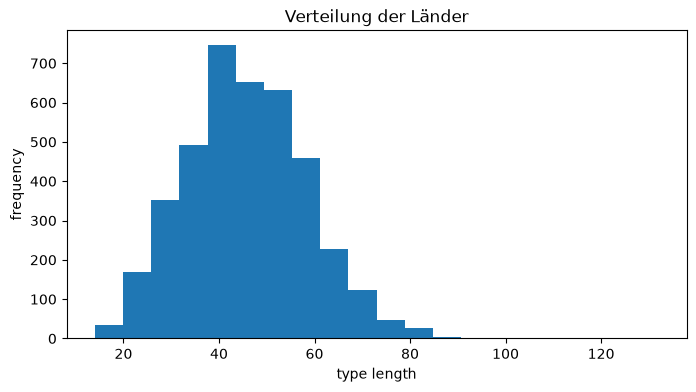

In [13]:
# New variable 'type_len' with the length of strings in 'type' (use .apply())
df['type_len']=df['type'].apply(len)

# Display variables 'type' and 'type_len'
df[['type','type_len']].head()

# Plot histogram of variable 'type_len'
fig, ax = plt.subplots(figsize=(8, 4))  
ax.hist(df['type_len'], bins=20)
ax.set_xlabel('type length')  
ax.set_ylabel('frequency')
ax.set_title('Verteilung der Länder')     
plt.show()

### Create binary (0/1) variable 'luxury_car'

In [14]:
# Create a pattern which can be used to search the variable 'type'
pattern = ('BUGATTI|FERRARI|ROLLS-ROYCE|LAMBORGHINI|BENTLEY|ASTON MARTIN|'
           'MASERATI|MCLAREN|PORSCHE')

# Create new variable 'luxury_car' as binary dummy (0/1) variable
df['luxury_car']=df['type'].str.contains(pat=pattern).astype(int)
#quasi erstelle eine neue spalte und markiere in der gem vordefiniertem Pattern welche Fahrzeuge dabei sind und welche nicht. dann fügen wir noch ".astype(int)" hinzu und dann haben wir jeweils statt True & False antworten 1&0

# Count the number of luxury cars
luxury_car_count=df['luxury_car'].sum()
print("number of Luxury Cars: ", luxury_car_count)
# Show values
df[['type','luxury_car']].loc[df['luxury_car']==1]

number of Luxury Cars:  299


,type,luxury_car
8,PORSCHE 911 TURBO CABRIO PDK (CABRIOLET),1
26,FERRARI 348 TS (CABRIOLET),1
57,PORSCHE 911 SC (COUPÉ),1
64,PORSCHE 911 CARRERA 4S PDK (COUPÉ),1
65,PORSCHE 911 CARRERA 4S CABRIO (CABRIOLET),1
...,...,...
3933,FERRARI 458 ITALIA 4.5 V8 (COUPÉ),1
3934,FERRARI 458 ITALIA 4.5 V8 (COUPÉ),1
3958,PORSCHE 911 TURBO (S) CABRIO (CABRIOLET),1
3964,BENTLEY ARNAGE RED LABEL (LIMOUSINE),1


### Create variable 'price_per_hp'

In [15]:
# Create variable 'price_per_hp' (round to 2 decimal places)
df['price_per_hp']=round(df['price']/df['hp'],2)

# Display variables 'price', 'hp' and 'price_per_hp'
df[['price_per_hp','hp','price']].head()


,price_per_hp,hp,price
0,91.84,245,22500
1,129.07,184,23749
2,60.46,306,18500
3,100.0,360,36000
4,192.46,252,48500


### Include current datetime as time stamp

In [16]:
# Include current datetime as time stamp in the format 'YYYY-MM-DD HH:MM:SS'
df['timestamp']=datetime.now().strftime('%Y-%m-%d %H:%M:%S')
df['timestamp'].head()

0    2026-11-05 16:01:34
1    2026-11-05 16:01:34
2    2026-11-05 16:01:34
3    2026-11-05 16:01:34
4    2026-11-05 16:01:34
Name: timestamp, dtype: str

## Discretization of numerical data

In [17]:
df.dtypes

url_short                     str
offer_id                    int64
scrape_dt                     str
type                          str
price_raw                     str
hp_raw                        str
init_regist                   str
mileage_raw                   str
fuel_type                     str
transmission                  str
dealer_name                   str
dealer_plz                  int64
dealer_city                   str
dealer_street_house_nr        str
dealer_telnr                  str
init_regist_my                str
init_regist_month         float64
init_regist_year          float64
init_regist_dt                str
mileage                     Int64
hp                          Int64
price                       Int64
type_len                    int64
luxury_car                  int64
price_per_hp              Float64
timestamp                     str
dtype: object

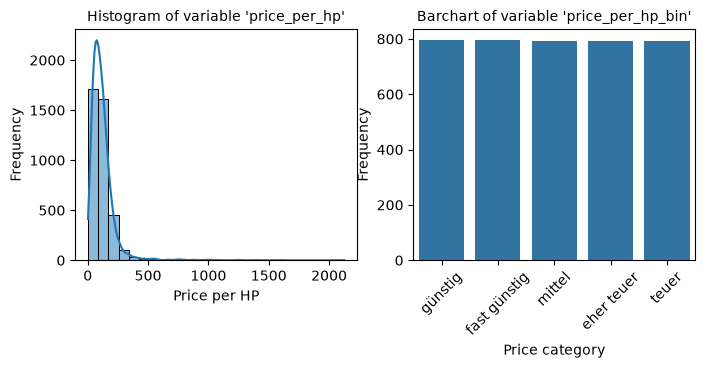

,price_per_hp,price_per_hp_bin
0,91.84,mittel
1,129.07,eher teuer
2,60.46,fast günstig
3,100.0,mittel
4,192.46,teuer


In [18]:
# Discretization of the variable 'price_per_hp' into 5 bins
# (note the 'qcut' function)

df['price_per_hp_bin']=pd.qcut(df['price_per_hp'], q=5,                  
                         labels=['günstig','fast günstig','mittel','eher teuer','teuer'])

# Show histogram of price_per_hp and barchart of variable 'price_per_hp_bin'
plt.figure(figsize=(8, 3))


# Create a 1x2 grid
plt.subplot(1, 2, 1)
sns.histplot(df['price_per_hp'], bins=25, kde=True)
plt.title("Histogram of variable 'price_per_hp'", fontsize=10)
plt.xlabel('Price per HP')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
sns.countplot(data=df, x='price_per_hp_bin', orient='v')
plt.title("Barchart of variable 'price_per_hp_bin'", fontsize=10)
plt.xlabel('Price category')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.show()

# Display variables 'price_per_hp' and 'price_per_hp_bin'
df[['price_per_hp', 'price_per_hp_bin']].head()


## One Hot Encoding

In [ ]:
# One Hot Encoding of the variable 'price_per_hp_bin'
df=pd.get_dummies(df,columns=['price_per_hp_bin'], drop_first=False)
#immer ganze Tabelle, da one hot encoding mehrere Spalten erzeugt. passt nicht in nur eine spalte
#columnns bezieht sich dann auf welche spalte one hot coding bekommen soll
#drop_first=False ist damit jede Kategorie eine eigene Spalte bekommt. sonst mit True würde die erste Spalte wegfallen. nimmt man für lineare Regression (Koeffizient). False für Kategorien und Entscheidungsbäume.

# Convert boolean values to integers (0 and 1)
dummy_cols = (df.filter(like='price_per_hp_bin').columns) #man will nicht die ganze tabelle in 1/0 umwandeln, deswegen dummy_cols
#in dummy_cols macht man mit der oberen die 5 KAtegorien rein
df[dummy_cols] = df[dummy_cols].astype(int) 
#das resultat überschreibt die alten true fals werte (df[dummy_cols] =)
#astype(int) macht es zu zahlen

# Show values of the new dummy variables
df[dummy_cols].head()

,price_per_hp_bin_günstig,price_per_hp_bin_fast günstig,price_per_hp_bin_mittel,price_per_hp_bin_eher teuer,price_per_hp_bin_teuer
0,0,0,1,0,0
1,0,0,0,1,0
2,0,1,0,0,0
3,0,0,1,0,0
4,0,0,0,0,1


## Scaling

### Min-Max Scaling

#### By hand

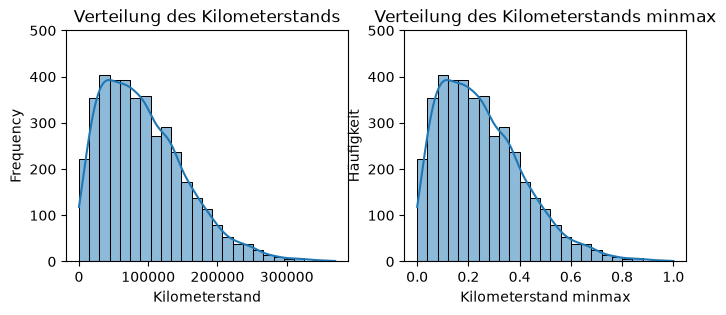

In [223]:
# Min-Max scaling of the variable 'mileage' (by hand)
df['mileage_scaled_minmax']=(df['mileage']-df['mileage'].min())/(df['mileage'].max()-df['mileage'].min())


# Histogram of the variable 'mileage' and 'mileage_scaled_minmax'
plt.figure(figsize=(8, 3))
plt.subplot(1, 2, 1) #heisst-> 1= es soll eine Reihe geben, 2= in dieser Reihe soll es 2 Grafiken geben, 1= jetzt zeichne ich die erste (links).
sns.histplot(data=df, x='mileage', bins=25, kde=True)
plt.title('Verteilung des Kilometerstands')
plt.xlabel('Kilometerstand')
plt.ylabel('Frequency')
plt.ylim(0, 500)

plt.subplot(1, 2, 2) 
sns.histplot(data=df, x='mileage_scaled_minmax', bins=25, kde=True)
plt.title('Verteilung des Kilometerstands minmax')
plt.xlabel('Kilometerstand minmax')
plt.ylabel('Häufigkeit')
plt.ylim(0, 500)
plt.show()


# Set the y-axis range for each subplot and add labels


# Display the plot


Die Aussage: Die Form ist genau gleich. Nur die Zahlen auf der x-Achse haben sich geändert.

links (Original)	
x-Achse	0 bis ca. 370'000 km	
Gipfel links, langer Schwanz nach rechts
Höhe der Balken	bis ca. 400

rechts (Min-Max)
0 bis 1
Gipfel links, langer Schwanz nach rechts
Höhe der Balken	bis ca. 400	

#### scikit-learn version

In [224]:
# Min-Max scaling of the variable 'mileage' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Check that the by-hand and scikit-learn versions give the same result


### Max-Absolute Scaling

#### By hand

In [225]:
# Max-Absolute scaling of the variable 'mileage' (by hand)


# Histogram of the variable 'mileage' and 'mileage_scaled_max_abs'


# Set the y-axis range for each subplot and add labels


# Display the plot


#### scikit-learn version

In [226]:
# Max-Absolute scaling of the variable 'mileage' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Check that the by-hand and scikit-learn versions give the same result


### Robust Scaling

#### By hand

In [227]:
# Robust scaling of the variable 'mileage' (by hand)


# Histogram of the variable 'mileage' and 'mileage_scaled_robust'


# Set the y-axis range for each subplot and add labels


# Display the plot


#### scikit-learn version

In [228]:
# Robust scaling of the variable 'mileage' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Check that the by-hand and scikit-learn versions give the same result


## Standardization

### Z-score Normalization

#### By hand

In [229]:
# Z-score Normalization of the variable 'mileage' (by hand)


# Histogram of the variable 'mileage' and 'mileage_scaled_z'


# Set the y-axis range for each subplot and add labels


# Display the plot


#### scikit-learn version

In [230]:
# Z-score Normalization of the variable 'mileage' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Note: pandas .std() divides by n-1, StandardScaler divides by n,
# so the results differ slightly


# Check against the by-hand formula with the standard deviation
# divided by n (ddof=0)


## Transformation

### Log-Transformation

In [231]:
# Log-Transformation of the variable 'mileage'


# Histogram of the variable 'mileage' and 'mileage_log'


# Set the y-axis range for each subplot and add labels


# Display the plot


### SQRT-Transformation

In [232]:
# SQRT-Transformation of the variable 'mileage'


# Histogram of the variable 'mileage' and 'mileage_sqrt'


# Set the y-axis range for each subplot and add labels


# Display the plot


### Box-Cox Transformation

In [233]:
# Import the boxcox function from scipy


# Box-Cox Transformation of the variable 'mileage'


# Histogram of the variable 'mileage' and 'mileage_boxcox'


# Set the y-axis range for each subplot and add labels


# Display the plot


## Combining & organizing data

### Reading car data with geocoded addresses

In [234]:
# Meaning of variables
# offer_id: unique identifier of the offer on autoscout24.ch
# lat: geographical latitude
# lon: geographical longitude
# bfs_number: official municipality id
# bfs_name: official municipality name

# Geocoded data (i.e. data with latitude and longitude)


# Show data


### Join geo-information to car data using .merge()

In [235]:
# Merge geo-information to the car data (the key is 'offer_id')


# Show data


### Reading municipality-level data from an .xlsx - file

In [236]:
# Meaning of variables:
# bfs_number: municipality id
# bfs_name: municipality name
# pop: number of residents
# pop_dens: population density per km2
# frg_pct: percentage foreigners
# emp: number of employees

# Read municipality-level data from the .xlsx file


# Show data


### Join municipality-level data to the car data data using .merge()

In [237]:
# Merge needs a key which must be identical in both data sets
# (here the key is 'bfs_number')


# Show data


### Sorting data

In [238]:
# Sorting data by 'price' and 'mileage' with highest price above
# (ascending=False)


# Show data


### Reshaping data

#### Reshaping data using .stack() and .unstack()

In [239]:
# Create a subset of the data (first 5 rows)


# Reshape the data using .stack()


# Reshape the data back using .unstack()


#### Reshaping data using .melt()

In [240]:
# Create a subset of the data (first 5 rows)


# Reshape the data using .melt()


### Pivoting data using .pivot_table()

In [241]:
# Create a pivot table with the mean values per fuel type


# Format the values to 2 decimal places with trailing zeros


# Display the pivot table


### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [242]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1064-azure
Datetime: 2026-11-05 16:26:02
Python Version: 3.11.18
-----------------------------------
